# Grid Search
- 머신러닝 모델의 최적 하이퍼파라미터를 자동으로 찾아주는 방법

Keras를 사용하여 **MNIST** 손글씨 숫자 분류 모델을 만들고, Scikit-learn의 GridSearchCV를 이용해 최적의 하이퍼파라미터(옵티마이저, 뉴런 수, 드롭아웃 비율) 찾기

MNIST 데이터셋은 손으로 쓴 0부터 9까지의 숫자 이미지로 이루어진, 머신러닝 및 딥러닝의 표준 벤치마크 데이터셋입니다.

- Kaggle MNIST: https://www.kaggle.com/datasets/hojjatk/mnist-dataset
- MNIST in CSV: https://drive.google.com/file/d/1eEKzfmEu6WKdRlohBQiqi3PhW_uIVJVP/view

In [1]:
from tensorflow.keras.datasets import mnist

from tensorflow.keras.optimizers import Adam, SGD
from sklearn.model_selection import GridSearchCV # Scikit-learn에서 제공하는 하이퍼파라미터 튜닝 도구
from scikeras.wrappers import KerasClassifier # Keras 모델을 Scikit-learn 모델처럼 동작하게 만드는 wrapper
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
 
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

In [2]:
# 데이터 불러오기 및 전처리
(X_train, y_train), (X_test, y_test) = mnist.load_data()
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

In [3]:
# 3개 데이터셋 shape 출력
print("=== Train Set ===")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\n=== Validation Set ===")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\n=== Test Set ===")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

=== Train Set ===
X_train: (48000, 28, 28)
y_train: (48000,)

=== Validation Set ===
X_val: (12000, 28, 28)
y_val: (12000,)

=== Test Set ===
X_test: (10000, 28, 28)
y_test: (10000,)


- 28x28 픽셀 크기의 흑백 이미지 48,000장으로 구성된 훈련 세트입니다.
- y_train은 1차원 배열이며, 그 안에는 48,000개의 정답 값(MNIST 데이터이므로 0부터 9까지의 숫자)와 같은 형태로 저장되어 있습니다.

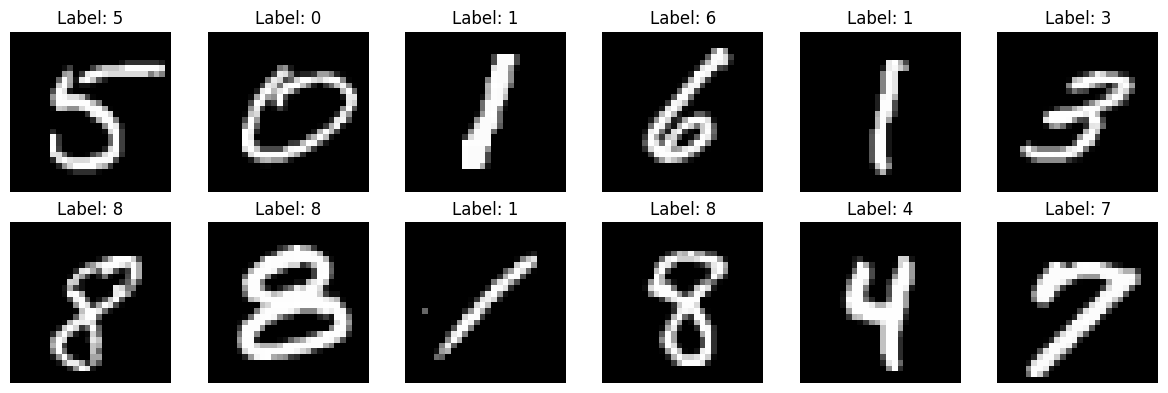

In [4]:
# 이미지 샘플 시각화 (처음 12개)
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 4))
for i in range(12):
    plt.subplot(2, 6, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
# plt.suptitle("MNIST 샘플 이미지 (Training Set)", fontsize=16, y=1.05)
plt.show()

In [5]:
# 데이터 전처리 (Flattening 및 Normalization)
X_train = X_train.reshape(-1, 28 * 28) / 255.0 # 2D 이미지를 1D로 펼치기 --> 픽셀 값을 0~255 범위에서 0.0~1.0 범위로 정규화
X_val = X_val.reshape(-1, 28 * 28) / 255.0
X_test = X_test.reshape(-1, 28 * 28) / 255.0

In [6]:
# 데이터 형태 확인
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")

X_train shape: (48000, 784)
y_train shape: (48000,)


- 무엇을: (48000, 28, 28) 모양을 (48000, 784) 모양으로 바꿉니다.
- 어떻게: 28x28 픽셀의 2D 이미지를 784개 픽셀(28*28=784)이 한 줄로 늘어선 1D 벡터(리스트)로 쭉 펼칩니다.
- 왜: 지금 사용하려는 Dense 같은 기본 신경망 레이어는 2D(가로, 세로) 이미지를 입력으로 받지 못합니다. "784개의 특징(feature) 리스트"라는 1D 형태의 데이터만 받을 수 있기 때문에, 데이터를 한 줄로 펴주는 것입니다.

In [7]:
# 모델 생성
def create_model(optimizer='adam', neurons=32, dropout=0.1):
    model = Sequential()
    model.add(Dense(neurons, activation='relu', input_shape=(784,)))
    model.add(Dropout(dropout))
    model.add(Dense(10, activation='softmax')) # 0~9까지 10개의 숫자를 분류
    model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

일반적인 다중 분류에서는 정답을 원-핫 벡터(예: [0,0,1,0])로 만들어야 하는데 (지잔 수업 사용한 *categorical_crossentropy* 예시 참고),
**sparse_categorical_crossentropy**는 원-핫 변환 없이 숫자 라벨 그대로 사용해도 됨.
  
  **!** 모델의 출력은 softmax 확률 값이어야 하고, 정답은 2, 7, 0 같은 정수 레이블이어야 한다.

In [8]:
# Keras로 만든 모델을 Scikit-learn 방식으로 사용할 수 있도록 래핑(wrap)
model = KerasClassifier(model=create_model, epochs=5, batch_size=128, verbose=0 )

**래퍼(wrapper)란?**

본래 객체나 기능을 그대로 두고, 바깥에서 새로운 형태·인터페이스를 씌워 다른 방식으로 사용할 수 있게 해주는 도구

In [9]:
# GridSearchCV가 테스트할 하이퍼파라미터 조합 정의 = 딕셔너리
param_grid = {
    "model__optimizer": ['adam', 'sgd'],
    "model__neurons": [16, 32],
    "model__dropout": [0.1, 0.25],
}

In [10]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) # Keras에서 자주 나타나는 입력 정의 방식 관련 경고 무시

# GridSearchCV 실행
grid = GridSearchCV(estimator=model, param_grid=param_grid, cv=3, scoring='accuracy')
grid_result = grid.fit(X_train, y_train)

- estimator=model: 사용할 기본 모델 GridSearchCV에 지정.
- param_grid=param_grid: 탐색할 하이퍼파라미터 값들의 집합을 전달.
- cv=3: 데이터를 3등분하여 3-fold 교차검증으로 평가한다.
  - 데이터를 3조각으로 나눈다 - A, B, C.
  - 학습과 검증을 세 번 반복한다: 1회차: A+B로 학습, C로 평가 / 2회차: A+C로 학습, B로 평가 / 3회차: B+C로 학습, A로 평가
  - 세 번의 평가 점수 평균을 내서
 
- scoring='accuracy': 모델 성능을 정확도로 비교하도록 점수 기준 설정.

In [11]:
# 결과 출력
print(f"Best Accuracy: {grid_result.best_score_:.4f}")
print("Best Parameters:", grid_result.best_params_)

Best Accuracy: 0.9401
Best Parameters: {'model__dropout': 0.1, 'model__neurons': 32, 'model__optimizer': 'adam'}


In [12]:
# 최적 모델 저장
best_model = grid_result.best_estimator_

In [13]:
# 최적 모델 요약
best_model.model_.summary()

Model: "sequential_24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_48 (Dense)                     │ (None, 32)                  │          25,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_24 (Dropout)                 │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_49 (Dense)                     │ (None, 10)                  │             330 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 76,352 (298.25 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 50,902 (198.84 KB)

- dense_48 (Dense): 입력 784개 × 뉴런 32개 + 32개의 bias = 25,120
- dropout_24 (Dropout): 단순히 뉴런 일부를 확률적으로 끄는 기능
- dense_49 (Dense) 출력층: 32 × 10 + 10 bias = 330

**학습 가능한 파라미터**
- → 여기서 25,450만 학습된다는 의미.
- → 나머지 50,902는 Optimizer의 내부 변수(모멘텀 등)라서 non-trainable로 표시됨.

In [14]:
# 테스트 데이터 예측
y_pred = best_model.predict(X_test)

In [15]:
# 혼동 행렬 계산
confusion_matrix(y_test, y_pred)

array([[ 960,    0,    0,    2,    0,    3,   11,    2,    1,    1],
       [   0, 1118,    2,    3,    0,    1,    3,    1,    7,    0],
       [   7,    2,  975,    8,    6,    1,    8,    9,   16,    0],
       [   2,    0,   19,  952,    1,    8,    0,   13,   10,    5],
       [   0,    0,    3,    0,  944,    1,   12,    4,    3,   15],
       [  10,    1,    5,   20,    3,  820,   14,    3,   11,    5],
       [   6,    3,    3,    1,    4,   10,  927,    0,    4,    0],
       [   0,    9,   23,    7,    1,    1,    0,  974,    1,   12],
       [   5,    6,   11,   24,    7,   11,   10,   10,  885,    5],
       [   8,    7,    2,   13,   23,    7,    1,   13,    6,  929]],
      dtype=int64)

In [16]:
# 테스트 정확도 계산
acc = accuracy_score(y_test, y_pred)
print(f"테스트 정확도: {acc:.4f}")

테스트 정확도: 0.9484
